# 🤼 Pro Kabaddi League - Exploratory Data Analysis & Visual Dashboard

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adarshgaurav1951/Kabaddi-Matches-EDA/blob/main/notebooks/01_cleaning.ipynb)

A modular, step-by-step visual analytics notebook. Every step includes clean data transformations and instant, publication-grade graphs that render reliably in Google Colab, GitHub, and Jupyter.


### ⚙️ Step 1: Environment Setup & Data Ingestion

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Styling for dark theme publication-ready visuals
plt.style.use('dark_background')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['axes.linewidth'] = 1.0

DARK_BG = '#0d1117'
CARD_BG = '#161b22'
TEXT_COLOR = '#e6edf3'
ACCENT_ORANGE = '#ff7b00'
ACCENT_CYAN = '#00e5ff'
ACCENT_BLUE = '#58a6ff'
ACCENT_GREEN = '#3fb950'
ACCENT_YELLOW = '#ffb703'

# Clone repository if running in Google Colab
if 'google.colab' in sys.modules and not os.path.exists('data'):
    print("Cloning Kabaddi repository into Google Colab...")
    os.system('git clone https://github.com/adarshgaurav1951/Kabaddi-Matches-EDA.git _repo')
    os.system('mkdir -p data/cleaned data/raw && cp -r _repo/data/cleaned/* data/cleaned/ && cp -r _repo/data/raw/* data/raw/ && rm -rf _repo')
    print("Datasets ready!")

DATA_DIR = 'data/cleaned' if os.path.exists('data/cleaned') else '../data/cleaned'
print(f"Data directory: {DATA_DIR}")


Data directory: ../data/cleaned


### 📂 Step 2: Load Cleaned Structured Datasets

In [2]:
df_matches = pd.read_csv(f"{DATA_DIR}/cleaned_matches.csv")
df_teams = pd.read_csv(f"{DATA_DIR}/cleaned_teams.csv")
df_players = pd.read_csv(f"{DATA_DIR}/cleaned_players.csv")

df_matches['date'] = pd.to_datetime(df_matches['date'], errors='coerce')

print(f"Matches: {df_matches.shape[0]:,} games | {df_matches.shape[1]} columns")
print(f"Teams:   {df_teams.shape[0]:,} team records | {df_teams.shape[1]} columns")
print(f"Players: {df_players.shape[0]:,} player records | {df_players.shape[1]} columns")


Matches: 684 games | 18 columns
Teams:   1,368 team records | 26 columns
Players: 16,892 player records | 29 columns


### 📊 Step 3: Executive KPI Summary

In [3]:
tot_matches = len(df_matches)
tot_points = int(df_teams['score'].sum())
tot_raids = int(df_teams['total_raids'].sum())
raid_strike = (df_teams['successful_raids'].sum() / tot_raids * 100) if tot_raids else 0
tot_tackles = int(df_teams['total_tackles'].sum())
tackle_eff = (df_teams['successful_tackles'].sum() / tot_tackles * 100) if tot_tackles else 0
tot_all_outs = int(df_teams['all_outs_inflicted'].sum())
tot_supers = int(df_teams['super_raids'].sum())

print("="*65)
print("              PRO KABADDI LEAGUE - EXECUTIVE KPIS")
print("="*65)
print(f"  • Total Matches Analyzed:   {tot_matches:,} matches")
print(f"  • Total Points Scored:      {tot_points:,} points ({tot_points/(tot_matches*2):.1f} pts/team)")
print(f"  • Overall Raid Strike Rate: {raid_strike:.1f}%")
print(f"  • Defensive Tackle Win Rate: {tackle_eff:.1f}%")
print(f"  • Total All-Outs Inflicted: {tot_all_outs:,} all-outs")
print(f"  • Total Super Raids:        {tot_supers:,} super raids")
print("="*65)


              PRO KABADDI LEAGUE - EXECUTIVE KPIS
  • Total Matches Analyzed:   684 matches
  • Total Points Scored:      43,560 points (31.8 pts/team)
  • Overall Raid Strike Rate: 34.3%
  • Defensive Tackle Win Rate: 38.3%
  • Total All-Outs Inflicted: 1,612 all-outs
  • Total Super Raids:        395 super raids


### 🏆 Step 4: Franchise Scoring Averages (Chart 1)

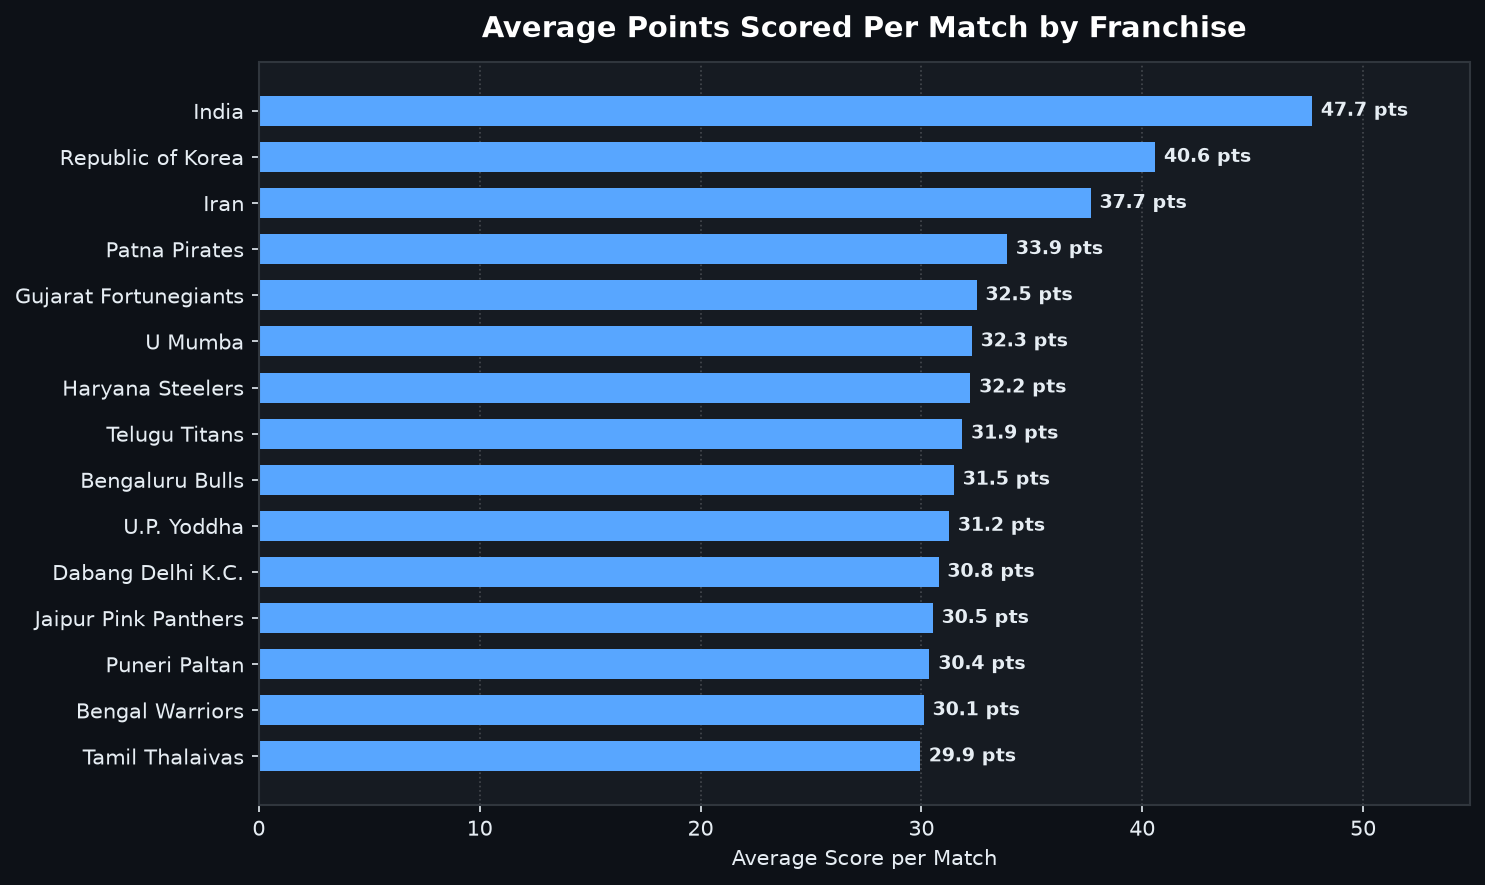

In [4]:
team_perf = df_teams.groupby('team_name').agg({
    'score': 'mean',
    'raid_points_total': 'mean',
    'tackle_points_total': 'mean',
    'all_outs_inflicted': 'sum',
    'match_id': 'count'
}).reset_index().rename(columns={'match_id': 'matches_played'})

team_perf = team_perf[team_perf['matches_played'] >= 10].sort_values(by='score', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

bars = ax.barh(team_perf['team_name'], team_perf['score'], color=ACCENT_BLUE, height=0.65, zorder=2)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.4, bar.get_y() + bar.get_height()/2, f"{w:.1f} pts",
            va='center', color=TEXT_COLOR, fontsize=9, fontweight='bold')

ax.set_xlim(0, team_perf['score'].max() * 1.15)
ax.set_title("Average Points Scored Per Match by Franchise", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Average Score per Match", fontsize=10, color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='x', linestyle=':', alpha=0.2)
plt.tight_layout()
plt.show()


### ⚔️ Step 5: Tactical Matrix - Raid Power vs. Defensive Wall (Chart 2)

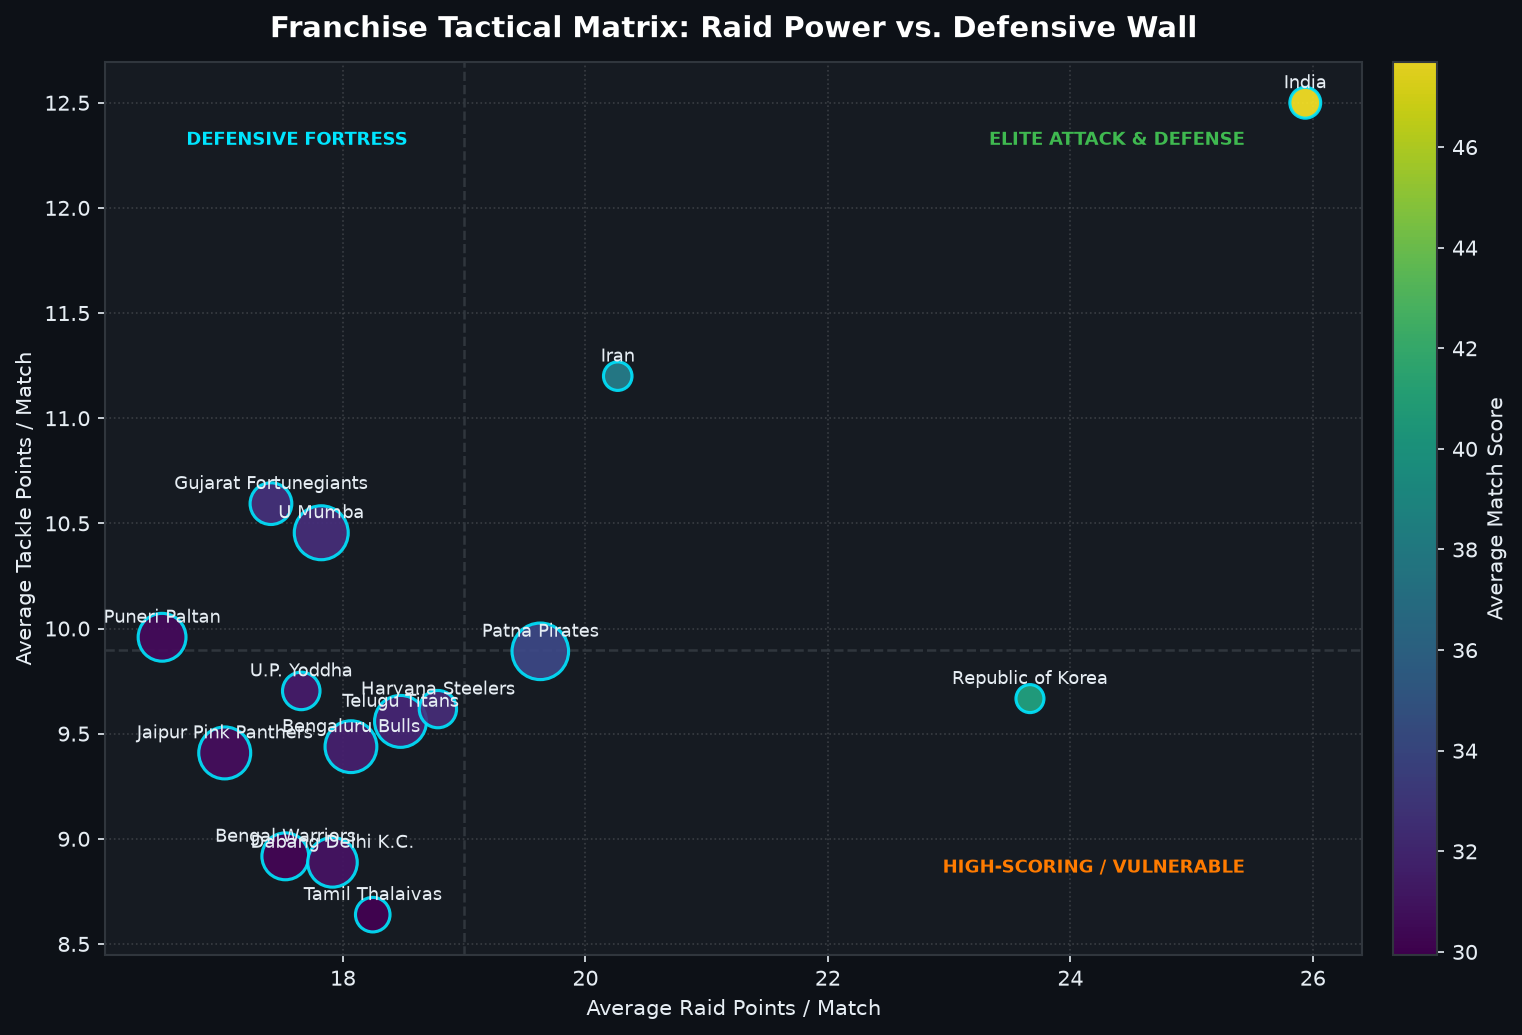

In [5]:
fig, ax = plt.subplots(figsize=(11, 7), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

mean_raid = team_perf['raid_points_total'].mean()
mean_tackle = team_perf['tackle_points_total'].mean()

ax.axvline(mean_raid, color='#30363d', linestyle='--', linewidth=1.2)
ax.axhline(mean_tackle, color='#30363d', linestyle='--', linewidth=1.2)

ax.text(team_perf['raid_points_total'].max() - 0.5, team_perf['tackle_points_total'].max() - 0.2,
        'ELITE ATTACK & DEFENSE', color=ACCENT_GREEN, fontsize=8.5, fontweight='bold', ha='right')
ax.text(team_perf['raid_points_total'].min() + 0.2, team_perf['tackle_points_total'].max() - 0.2,
        'DEFENSIVE FORTRESS', color=ACCENT_CYAN, fontsize=8.5, fontweight='bold', ha='left')
ax.text(team_perf['raid_points_total'].max() - 0.5, team_perf['tackle_points_total'].min() + 0.2,
        'HIGH-SCORING / VULNERABLE', color=ACCENT_ORANGE, fontsize=8.5, fontweight='bold', ha='right')

scatter = ax.scatter(
    team_perf['raid_points_total'],
    team_perf['tackle_points_total'],
    s=team_perf['all_outs_inflicted'] * 3.5 + 100,
    c=team_perf['score'],
    cmap='viridis',
    edgecolors=ACCENT_CYAN,
    linewidth=1.5,
    alpha=0.9,
    zorder=3
)

for _, row in team_perf.iterrows():
    ax.annotate(row['team_name'], (row['raid_points_total'], row['tackle_points_total']),
                xytext=(0, 7), textcoords="offset points", fontsize=8.5, color=TEXT_COLOR, ha='center')

cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Average Match Score', color=TEXT_COLOR, fontsize=10)
cbar.ax.yaxis.set_tick_params(color=TEXT_COLOR)
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color=TEXT_COLOR)

ax.set_title("Franchise Tactical Matrix: Raid Power vs. Defensive Wall", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Average Raid Points / Match", fontsize=10, color=TEXT_COLOR)
ax.set_ylabel("Average Tackle Points / Match", fontsize=10, color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### ⚡ Step 6: Top Raiders by Points & Points Per Raid (Chart 3)

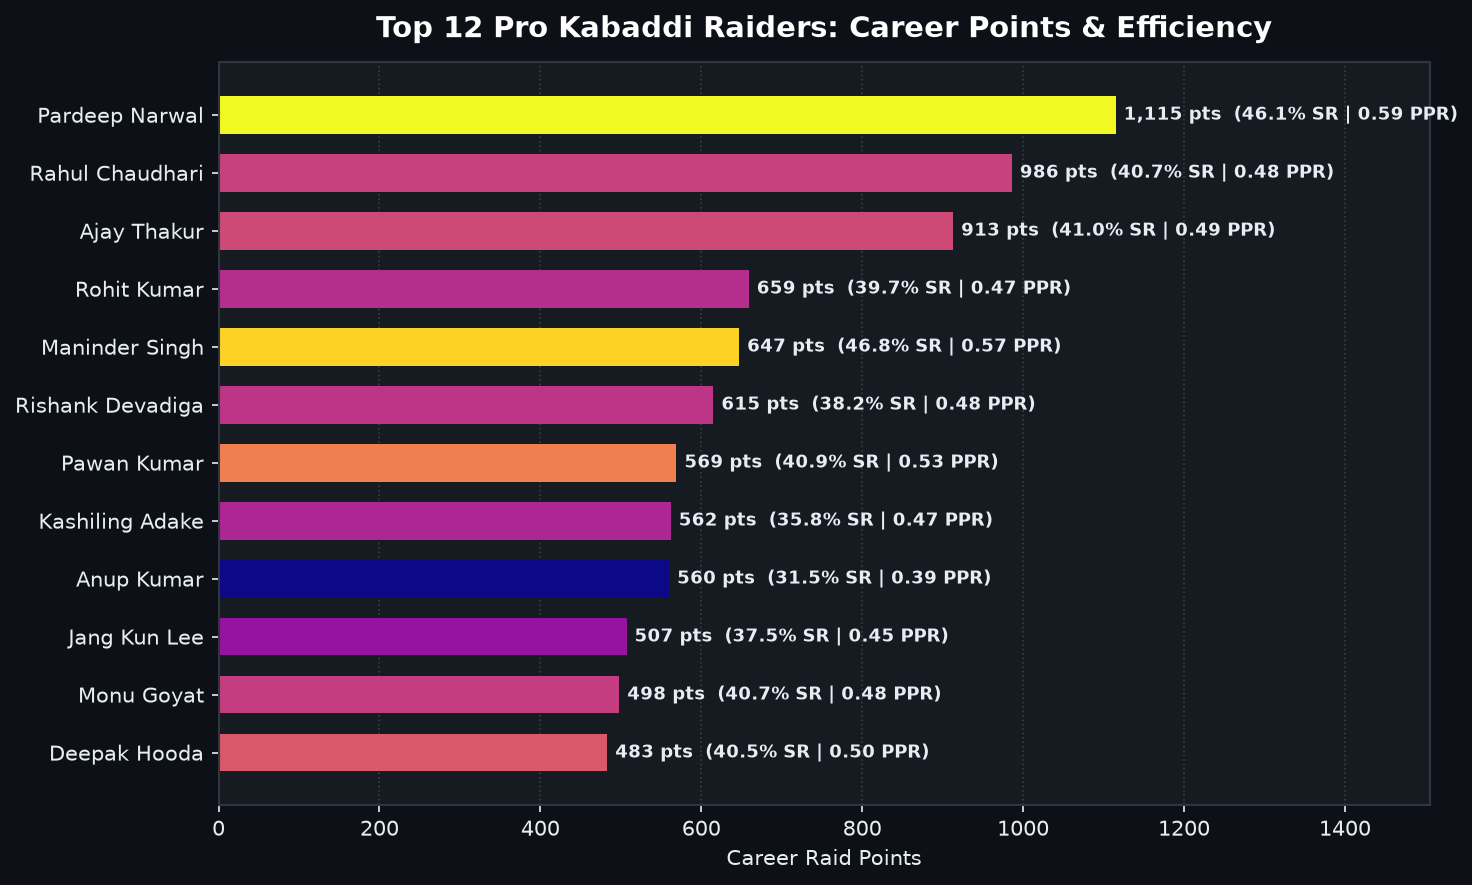

In [6]:
raider_agg = df_players.groupby(['player_name', 'player_category']).agg({
    'player_raid_points_total': 'sum',
    'player_raids_total': 'sum',
    'player_raids_successful': 'sum'
}).reset_index()

raiders_q = raider_agg[raider_agg['player_raids_total'] >= 50].copy()
raiders_q['strike_rate'] = (raiders_q['player_raids_successful'] / raiders_q['player_raids_total']) * 100
raiders_q['ppr'] = raiders_q['player_raid_points_total'] / raiders_q['player_raids_total']
top12_raiders = raiders_q.sort_values(by='player_raid_points_total', ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

norm = plt.Normalize(top12_raiders['ppr'].min(), top12_raiders['ppr'].max())
colors = plt.cm.plasma(norm(top12_raiders['ppr']))
bars = ax.barh(top12_raiders['player_name'], top12_raiders['player_raid_points_total'], color=colors, height=0.65, zorder=2)

for bar, (_, row) in zip(bars, top12_raiders.iterrows()):
    w = bar.get_width()
    ax.text(w + 10, bar.get_y() + bar.get_height()/2,
            f"{int(w):,} pts  ({row['strike_rate']:.1f}% SR | {row['ppr']:.2f} PPR)",
            va='center', color=TEXT_COLOR, fontsize=8.5, fontweight='bold')

ax.set_xlim(0, top12_raiders['player_raid_points_total'].max() * 1.35)
ax.set_title("Top 12 Pro Kabaddi Raiders: Career Points & Efficiency", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Career Raid Points", fontsize=10, color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='x', linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### 🎯 Step 7: Physical Touch Points vs. Bonus Line Crossings (Chart 4)

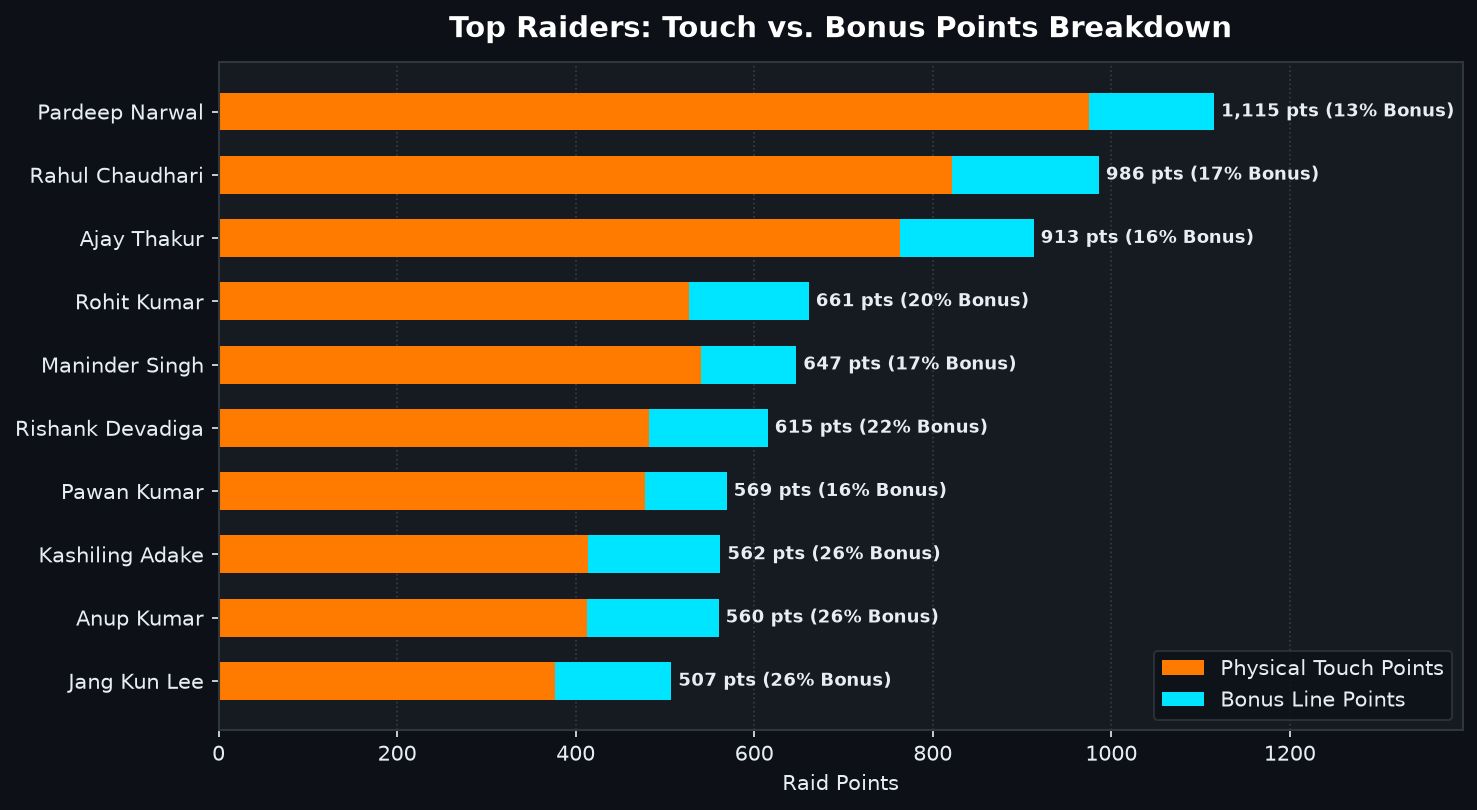

In [7]:
touch_bonus = df_players.groupby('player_name').agg({
    'player_raid_points_touch': 'sum',
    'player_raid_points_raid_bonus': 'sum',
    'player_raid_points_total': 'sum'
}).reset_index().sort_values(by='player_raid_points_total', ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

ax.barh(touch_bonus['player_name'], touch_bonus['player_raid_points_touch'],
        color=ACCENT_ORANGE, label='Physical Touch Points', height=0.6, zorder=2)
ax.barh(touch_bonus['player_name'], touch_bonus['player_raid_points_raid_bonus'],
        left=touch_bonus['player_raid_points_touch'], color=ACCENT_CYAN,
        label='Bonus Line Points', height=0.6, zorder=2)

for _, row in touch_bonus.iterrows():
    tot = row['player_raid_points_total']
    pct_bonus = (row['player_raid_points_raid_bonus'] / tot * 100) if tot else 0
    ax.text(tot + 8, row['player_name'], f"{int(tot):,} pts ({pct_bonus:.0f}% Bonus)",
            va='center', color=TEXT_COLOR, fontsize=8.5, fontweight='bold')

ax.set_xlim(0, touch_bonus['player_raid_points_total'].max() * 1.25)
ax.set_title("Top Raiders: Touch vs. Bonus Points Breakdown", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Raid Points", fontsize=10, color=TEXT_COLOR)
ax.legend(facecolor=DARK_BG, edgecolor='#30363d', labelcolor=TEXT_COLOR, loc='lower right')
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='x', linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### 🛡️ Step 8: Top Defenders - Tackle Volume & Win Rate % (Chart 5)

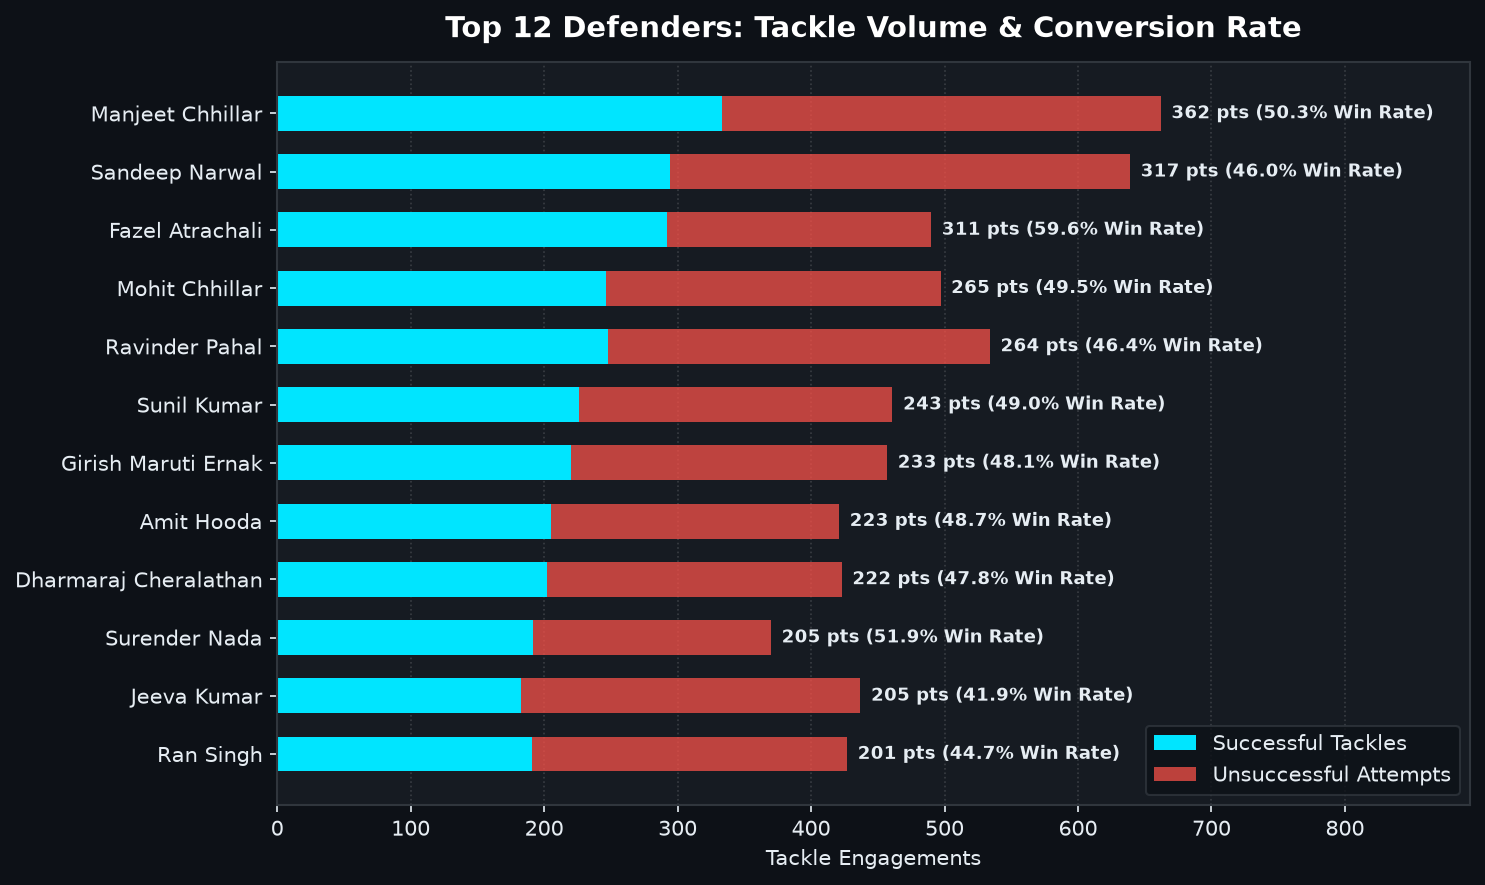

In [8]:
def_agg = df_players.groupby(['player_name', 'player_category']).agg({
    'player_tackle_points_total': 'sum',
    'player_tackles_total': 'sum',
    'player_tackles_successful': 'sum',
    'player_tackles_unsuccessful': 'sum'
}).reset_index()

def_q = def_agg[def_agg['player_tackles_total'] >= 30].copy()
def_q['conversion'] = (def_q['player_tackles_successful'] / def_q['player_tackles_total']) * 100
top12_def = def_q.sort_values(by='player_tackle_points_total', ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

ax.barh(top12_def['player_name'], top12_def['player_tackles_successful'],
        color=ACCENT_CYAN, label='Successful Tackles', height=0.6, zorder=2)
ax.barh(top12_def['player_name'], top12_def['player_tackles_unsuccessful'],
        left=top12_def['player_tackles_successful'], color='#f85149', alpha=0.75,
        label='Unsuccessful Attempts', height=0.6, zorder=2)

for _, row in top12_def.iterrows():
    tot = row['player_tackles_total']
    ax.text(tot + 8, row['player_name'],
            f"{int(row['player_tackle_points_total'])} pts ({row['conversion']:.1f}% Win Rate)",
            va='center', color=TEXT_COLOR, fontsize=8.5, fontweight='bold')

ax.set_xlim(0, top12_def['player_tackles_total'].max() * 1.35)
ax.set_title("Top 12 Defenders: Tackle Volume & Conversion Rate", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Tackle Engagements", fontsize=10, color=TEXT_COLOR)
ax.legend(facecolor=DARK_BG, edgecolor='#30363d', labelcolor=TEXT_COLOR, loc='lower right')
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='x', linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### ⏱️ Step 9: Match Victory Margin Distribution (Chart 6)

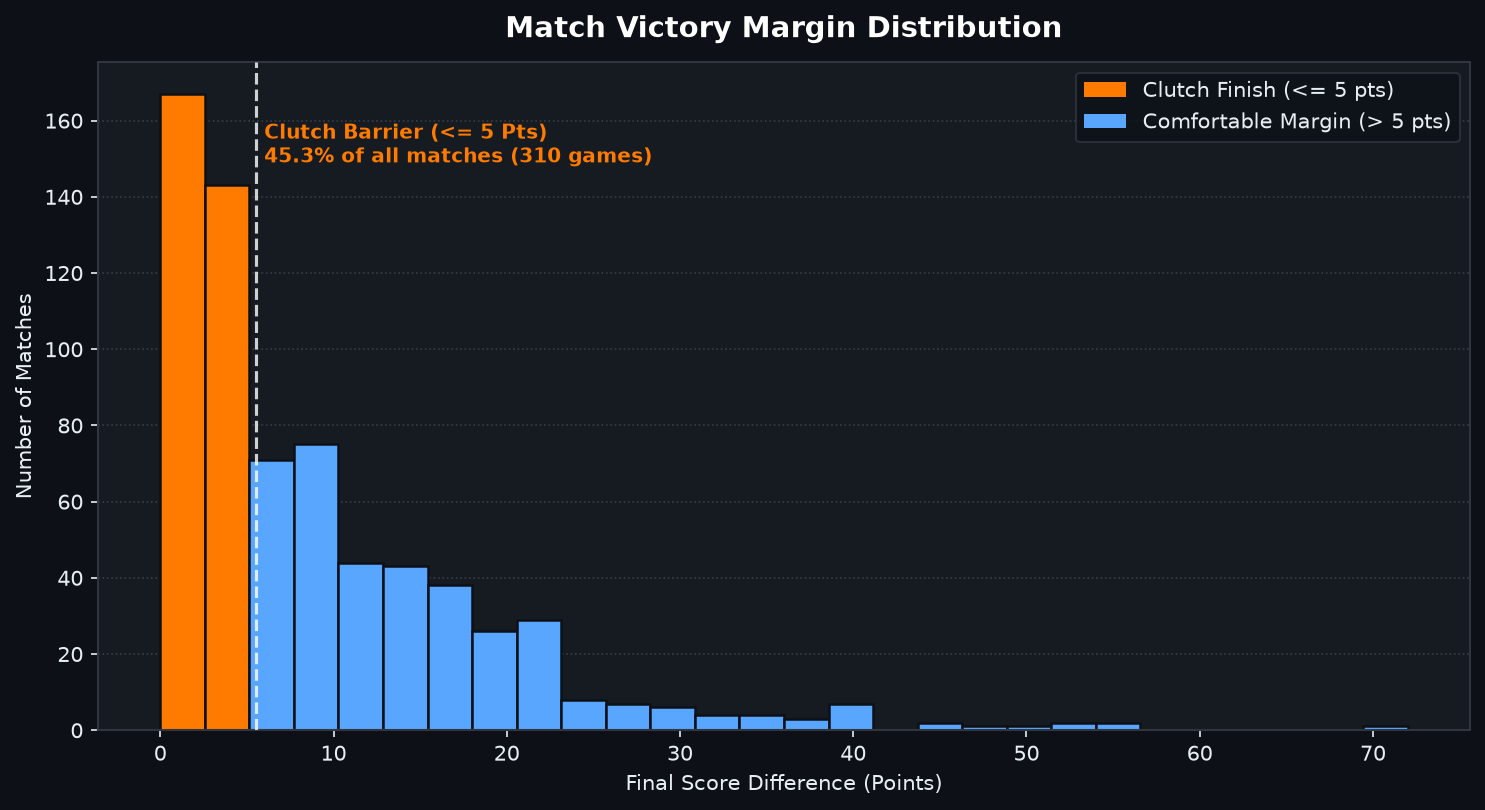

In [9]:
team_margins = df_teams.groupby('match_id')['score'].agg(
    lambda s: abs(s.iloc[0] - s.iloc[1]) if len(s) == 2 else 0
).reset_index().rename(columns={'score': 'margin'})

close_count = (team_margins['margin'] <= 5).sum()
close_pct = (close_count / len(team_margins)) * 100

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

n, bins, patches_list = ax.hist(team_margins['margin'], bins=28, edgecolor=DARK_BG, linewidth=1.2, zorder=2)
for patch, b in zip(patches_list, bins):
    patch.set_facecolor(ACCENT_ORANGE if b <= 5 else ACCENT_BLUE)

ax.axvline(5.5, color='#ffffff', linestyle='--', linewidth=1.5, alpha=0.8, zorder=3)
ax.text(6.0, ax.get_ylim()[1] * 0.85, f"Clutch Barrier (<= 5 Pts)\n{close_pct:.1f}% of all matches ({close_count} games)",
        color=ACCENT_ORANGE, fontsize=9.5, fontweight='bold')

custom_lines = [patches.Patch(facecolor=ACCENT_ORANGE, label='Clutch Finish (<= 5 pts)'),
                patches.Patch(facecolor=ACCENT_BLUE, label='Comfortable Margin (> 5 pts)')]
ax.legend(handles=custom_lines, facecolor=DARK_BG, edgecolor='#30363d', labelcolor=TEXT_COLOR, loc='upper right')

ax.set_title("Match Victory Margin Distribution", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("Final Score Difference (Points)", fontsize=10, color=TEXT_COLOR)
ax.set_ylabel("Number of Matches", fontsize=10, color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='y', linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### 💥 Step 10: Impact of All-Outs on Final Score (Chart 7)

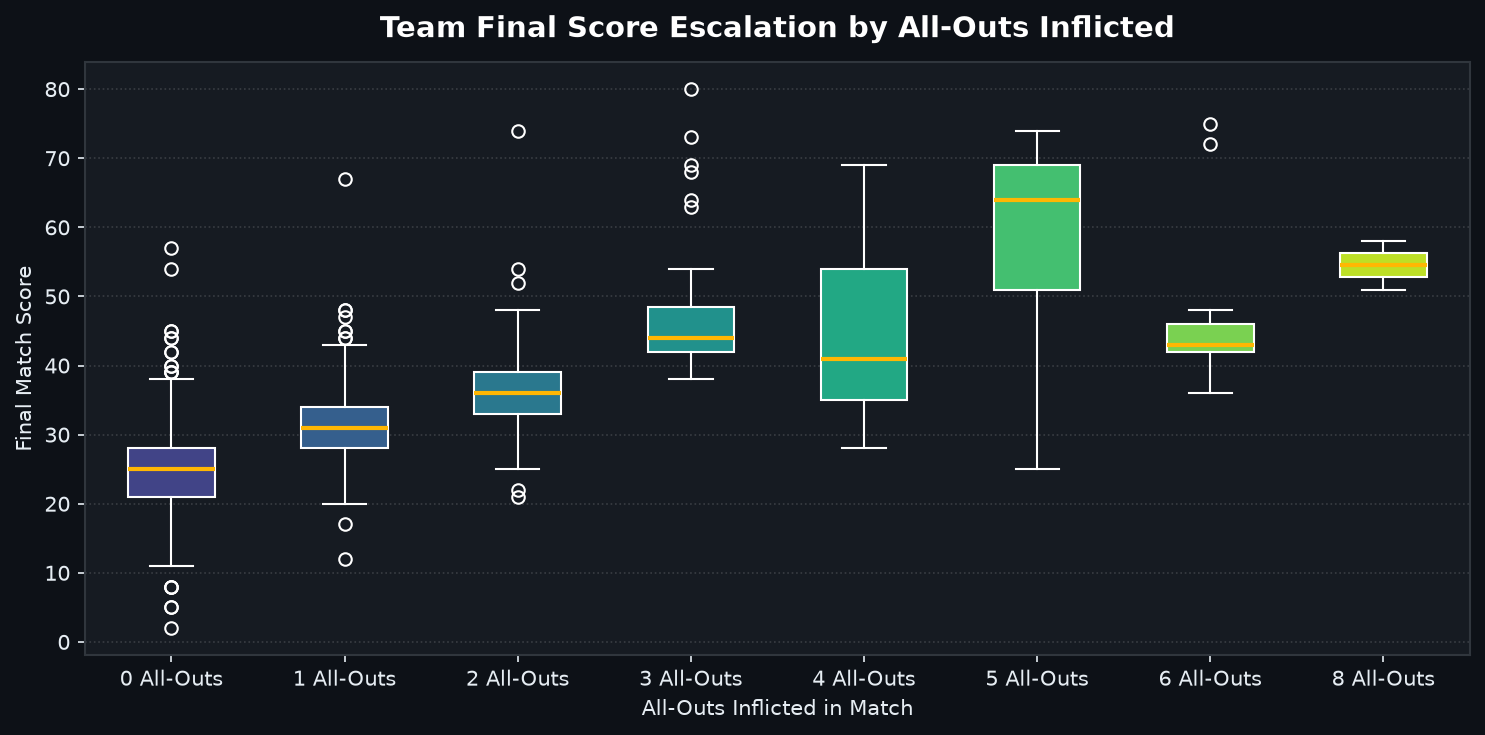

In [10]:
fig, ax = plt.subplots(figsize=(10, 5), facecolor=DARK_BG)
ax.set_facecolor(CARD_BG)

allouts = sorted(df_teams['all_outs_inflicted'].unique())
data_by_allout = [df_teams[df_teams['all_outs_inflicted'] == a]['score'] for a in allouts]

box = ax.boxplot(data_by_allout, tick_labels=[f"{a} All-Outs" for a in allouts],
                 patch_artist=True, medianprops=dict(color=ACCENT_YELLOW, linewidth=2))

palette = plt.cm.viridis(np.linspace(0.2, 0.9, len(allouts)))
for patch, color in zip(box['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_edgecolor('#ffffff')

ax.set_title("Team Final Score Escalation by All-Outs Inflicted", fontsize=14, fontweight='bold', color='#ffffff', pad=12)
ax.set_xlabel("All-Outs Inflicted in Match", fontsize=10, color=TEXT_COLOR)
ax.set_ylabel("Final Match Score", fontsize=10, color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR)
ax.grid(True, axis='y', linestyle=':', alpha=0.15)
plt.tight_layout()
plt.show()


### 🚀 Step 11: (Optional) Power BI / Tableau Drag-and-Drop Builder

In [11]:
# Run this cell if you want a drag-and-drop Power BI visual editor right inside Colab!
try:
    import pygwalker as pyg
    pyg.walk(df_teams)
except ImportError:
    print("Install pygwalker with: !pip install pygwalker -q")


Install pygwalker with: !pip install pygwalker -q
